In [1]:
import sklearn 
import numpy as np
from sklearn.datasets import load_iris
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [3]:

iris = load_iris()
X = iris.data
y = iris.target

In [9]:
#iris.data

In [10]:
#iris.feature_names

In [12]:
#print(X.shape)

In [17]:
#iris.target_names

In [5]:
encoder = OneHotEncoder(sparse_output=False)
y = encoder.fit_transform(y.reshape(-1,1))

In [7]:
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [9]:
# Split data for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [27]:
w1 = np.random.rand(4,5)
b1 = np.zeros(5)
print(b1.shape)

(5,)


In [29]:
w2 = np.random.rand(5,3)
b2 = np.zeros(3)
print(b2.shape)

(3,)


In [15]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def derivative_sigmoid(a):
    s = sigmoid(a)
    return s * (1 - s)

In [17]:
epochs = 5000
lr = 0.1

In [19]:
for epoch in range(epochs):

    for i in range(len(X_train)):

        x = X_train[i]
        target = y_train[i]

        # Hidden Layer
        h1 = np.dot(x, w1) + b1
        a1 = sigmoid(h1)

        # Output Layer
        h2 = np.dot(a1, w2) + b2
        a2 = sigmoid(h2)

        # Backpropagation

       # o2 = (a2 - target) * derivative_sigmoid(a2)
        o2 = (a2 - target) * derivative_sigmoid(h2)

       # o1 = derivative_sigmoid(a1) * np.dot(w2, o2)
        o1 = derivative_sigmoid(h1) * np.dot(w2, o2)

        # Update output weights
        w2 -= lr * np.outer(a1, o2)
        b2 -= lr * o2

        # Update hidden weights
        w1 -= lr * np.outer(x, o1)
        b1 -= lr * o1

In [21]:
h1 = np.dot(x, w1)
h2 = np.dot(a1, w2)

In [23]:
def predict(X):

    h1 = sigmoid(np.dot(X, w1) + b1)

    h2 = sigmoid(np.dot(h1, w2) + b2)

    return np.argmax(h2, axis=1)
y_pred = predict(X_test)

y_true = np.argmax(y_test, axis=1)

accuracy = np.mean(y_pred == y_true)

print("Accuracy:", accuracy)

Accuracy: 1.0


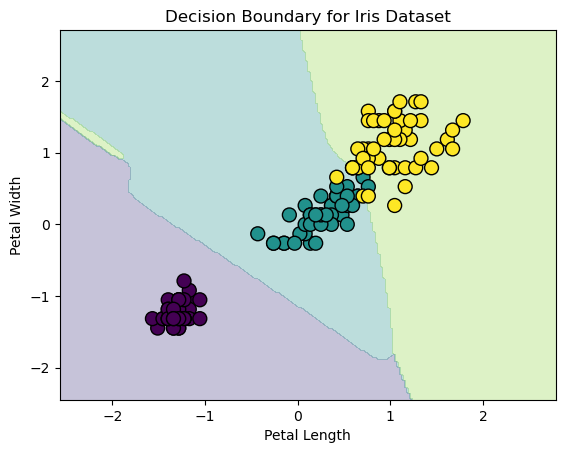

In [25]:
import matplotlib.pyplot as plt

# We will plot:
# x-axis = Petal Length
# y-axis = Petal Width

feature1 = 2   # Petal length
feature2 = 3   # Petal width
#feature1 = 0 # Sepal Length
#feature2 = 1 # Sepal width

# Create a grid
x_min = X[:, feature1].min() - 1
x_max = X[:, feature1].max() + 1

y_min = X[:, feature2].min() - 1
y_max = X[:, feature2].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Create grid points
grid = np.c_[xx.ravel(), yy.ravel()]

# We need 4 features because our neural network expects 4 inputs.
# Start by creating 4-feature input for every grid point.

grid_full = np.zeros((grid.shape[0], 4))

# Put the two plotted features into the grid
grid_full[:, feature1] = grid[:, 0]
grid_full[:, feature2] = grid[:, 1]

# Keep the other two features at their mean values
grid_full[:, 0] = X[:, 0].mean()
grid_full[:, 1] = X[:, 1].mean()

# Forward pass through the neural network

a1_grid = sigmoid(np.dot(grid_full, w1) + b1)

a2_grid = sigmoid(np.dot(a1_grid, w2) + b2)

# Choose the class with the highest output
Z = np.argmax(a2_grid, axis=1)

# Reshape predictions back into the grid
Z = Z.reshape(xx.shape)

# Plot decision regions
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    levels=[-0.5, 0.5, 1.5, 2.5]
)

# Plot actual Iris data
plt.scatter(
    X[:, feature1],
    X[:, feature2],
    c=np.argmax(y, axis=1),
    edgecolor='k',
    s=100
)

plt.xlabel("Petal Length")
plt.ylabel("Petal Width")
plt.title("Decision Boundary for Iris Dataset")

plt.show()

In [18]:
x= 1

In [19]:
xx= 1


In [20]:
np.mean(x==xx)

1.0